# Introduction

Since Jan. 1, 2015, [The Washington Post](https://www.washingtonpost.com/) has been compiling a database of every fatal shooting in the US by a police officer in the line of duty. 

<center><img src=https://i.imgur.com/sX3K62b.png></center>

While there are many challenges regarding data collection and reporting, The Washington Post has been tracking more than a dozen details about each killing. This includes the race, age and gender of the deceased, whether the person was armed, and whether the victim was experiencing a mental-health crisis. The Washington Post has gathered this supplemental information from law enforcement websites, local new reports, social media, and by monitoring independent databases such as "Killed by police" and "Fatal Encounters". The Post has also conducted additional reporting in many cases.

There are 4 additional datasets: US census data on poverty rate, high school graduation rate, median household income, and racial demographics. [Source of census data](https://factfinder.census.gov/faces/nav/jsf/pages/community_facts.xhtml).

### Upgrade Plotly

Run the cell below if you are working with Google Colab

In [1]:
# %pip install --upgrade plotly

## Import Statements

In [2]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import plotly.graph_objects as go

mpl.style.use('ggplot')

from collections import Counter

## Notebook Presentation

In [3]:
pd.options.display.float_format = '{:,.2f}'.format

## Load the Data

In [4]:
df_hh_income = pd.read_csv('../data/Median_Household_Income_2015.csv', encoding="windows-1252")
df_pct_poverty = pd.read_csv('../data/Pct_People_Below_Poverty_Level.csv', encoding="windows-1252")
df_pct_completed_hs = pd.read_csv('../data/Pct_Over_25_Completed_High_School.csv', encoding="windows-1252")
df_share_race_city = pd.read_csv('../data/Share_of_Race_By_City.csv', encoding="windows-1252")
df_fatalities = pd.read_csv('../data/Deaths_by_Police_US.csv', encoding="windows-1252")

# Preliminary Data Exploration

In [5]:
print(f'The shape of Median Household Income DataFrame: {df_hh_income.shape}')
print(f'The shape of Pct People Below Level DataFrame: {df_pct_poverty.shape}')
print(f'The shape of Pct Over 25 Completed High School DataFrame: {df_pct_completed_hs.shape}')
print(f'The shape of Share of Race By City DataFrame: {df_share_race_city.shape}')
print(f'The shape of Deaths By Police US DataFrame: {df_fatalities.shape}')

The shape of Median Household Income DataFrame: (29322, 3)
The shape of Pct People Below Level DataFrame: (29329, 3)
The shape of Pct Over 25 Completed High School DataFrame: (29329, 3)
The shape of Share of Race By City DataFrame: (29268, 7)
The shape of Deaths By Police US DataFrame: (2535, 14)


In [6]:
def dataframes_columns(dataframes):
    for dataframe in dataframes:
        for column in dataframe.columns:
            print(column, end=' | ')
        print('\n')

dataframes_columns([df_hh_income, df_pct_poverty, df_pct_completed_hs, df_share_race_city, df_fatalities])

Geographic Area | City | Median Income | 

Geographic Area | City | poverty_rate | 

Geographic Area | City | percent_completed_hs | 

Geographic area | City | share_white | share_black | share_native_american | share_asian | share_hispanic | 

id | name | date | manner_of_death | armed | age | gender | race | city | state | signs_of_mental_illness | threat_level | flee | body_camera | 



In [7]:
print(f'Nan Values Median Household Income DataFrame? {df_hh_income.isna().sum().sum()}')
print(f'Nan Values Pct People Below Level DataFrame? {df_pct_poverty.isna().sum().sum()}')
print(f'Nan Values Pct Over 25 Completed High School DataFrame? {df_pct_completed_hs.isna().sum().sum()}')
print(f'Nan Values Share of Race By City DataFrame? {df_share_race_city.isna().sum().sum()}')
print(f'Nan Values Deaths By Police US DataFrame? {df_fatalities.isna().sum().sum()}')


Nan Values Median Household Income DataFrame? 51
Nan Values Pct People Below Level DataFrame? 0
Nan Values Pct Over 25 Completed High School DataFrame? 0
Nan Values Share of Race By City DataFrame? 0
Nan Values Deaths By Police US DataFrame? 346


In [8]:
print(f'Duplicated Values Median Household Income DataFrame? {df_hh_income.duplicated().sum()}')
print(f'Duplicated Values Pct People Below Level DataFrame? {df_pct_poverty.duplicated().sum()}')
print(f'Duplicated Values Pct Over 25 Completed High School DataFrame? {df_pct_completed_hs.duplicated().sum()}')
print(f'Duplicated Values Share of Race By City DataFrame? {df_share_race_city.duplicated().sum()}')
print(f'Duplicated Values Deaths By Police US DataFrame? {df_fatalities.duplicated().sum()}')

Duplicated Values Median Household Income DataFrame? 0
Duplicated Values Pct People Below Level DataFrame? 0
Duplicated Values Pct Over 25 Completed High School DataFrame? 0
Duplicated Values Share of Race By City DataFrame? 0
Duplicated Values Deaths By Police US DataFrame? 0


## Data Cleaning - Check for Missing Values and Duplicates

In [9]:
df_hh_income[df_hh_income.isna().any(axis=1)]

,Geographic Area,City,Median Income
29119,WY,Albany CDP,NaN
29121,WY,Alcova CDP,NaN
29123,WY,Alpine Northeast CDP,NaN
29126,WY,Antelope Hills CDP,NaN
29129,WY,Arlington CDP,NaN
29130,WY,Arrowhead Springs CDP,NaN
29132,WY,Atlantic City CDP,NaN
29133,WY,Auburn CDP,NaN
29139,WY,Bedford CDP,NaN
29140,WY,Bessemer Bend CDP,NaN


In [10]:
df_hh_income = df_hh_income.fillna(0)

In [11]:
df_fatalities[df_fatalities.isna().any(axis=1)]

,id,name,date,manner_of_death,armed,age,gender,race,city,state,signs_of_mental_illness,threat_level,flee,body_camera
59,110,William Campbell,25/01/15,shot,gun,59.00,M,NaN,Winslow,NJ,False,attack,Not fleeing,False
124,584,Alejandro Salazar,20/02/15,shot,gun,NaN,M,H,Houston,TX,False,attack,Car,False
241,244,John Marcell Allen,30/03/15,shot,gun,54.00,M,NaN,Boulder City,NV,False,attack,Not fleeing,False
266,534,Mark Smith,09/04/15,shot and Tasered,vehicle,54.00,M,NaN,Kellyville,OK,False,attack,Other,False
340,433,Joseph Roy,07/05/15,shot,knife,72.00,M,NaN,Lawrenceville,GA,True,other,Not fleeing,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2528,2812,Alejandro Alvarado,27/07/17,shot,knife,NaN,M,H,Chowchilla,CA,False,attack,Not fleeing,False
2529,2819,Brian J. Skinner,28/07/17,shot,knife,32.00,M,NaN,Glenville,NY,True,other,Not fleeing,False
2530,2822,Rodney E. Jacobs,28/07/17,shot,gun,31.00,M,NaN,Kansas City,MO,False,attack,Not fleeing,False
2531,2813,TK TK,28/07/17,shot,vehicle,NaN,M,NaN,Albuquerque,NM,False,attack,Car,False


In [12]:
df_fatalities = df_fatalities.fillna(0)

# The Poverty Rate in each US State


In [13]:
df_pct_poverty.poverty_rate = pd.to_numeric(df_pct_poverty.poverty_rate,errors='coerce')

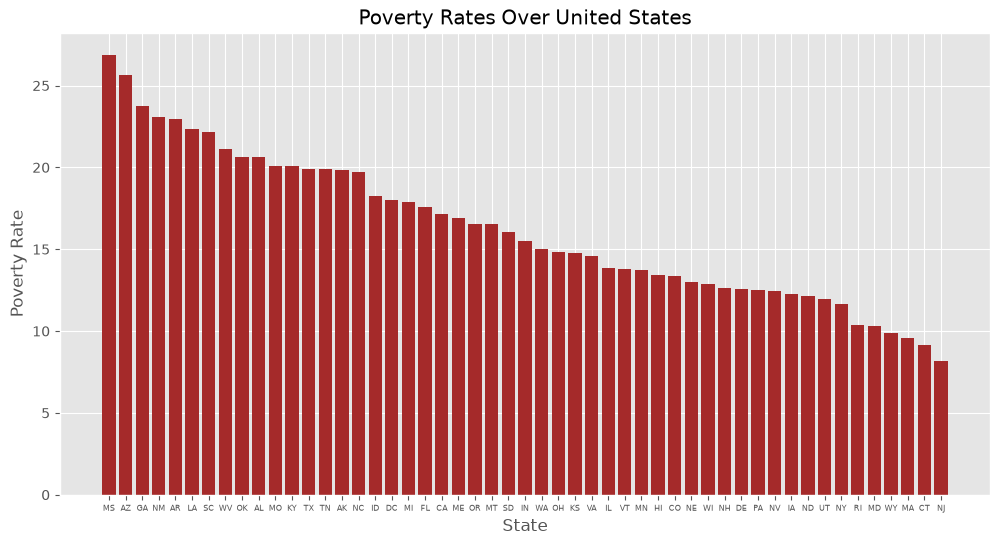

In [14]:
poverty_by_stats = df_pct_poverty.groupby('Geographic Area').poverty_rate.mean().sort_values(ascending=False)

plt.figure(figsize=(12,6))

plt.bar(x=poverty_by_stats.index, height=poverty_by_stats.values, color='brown')

plt.xticks(fontsize=6)
plt.title('Poverty Rates Over United States')
plt.xlabel('State')
plt.ylabel('Poverty Rate')

plt.show()

# High School Graduation Rate by US State



In [15]:
df_pct_completed_hs.percent_completed_hs = pd.to_numeric(df_pct_completed_hs.percent_completed_hs,errors='coerce')

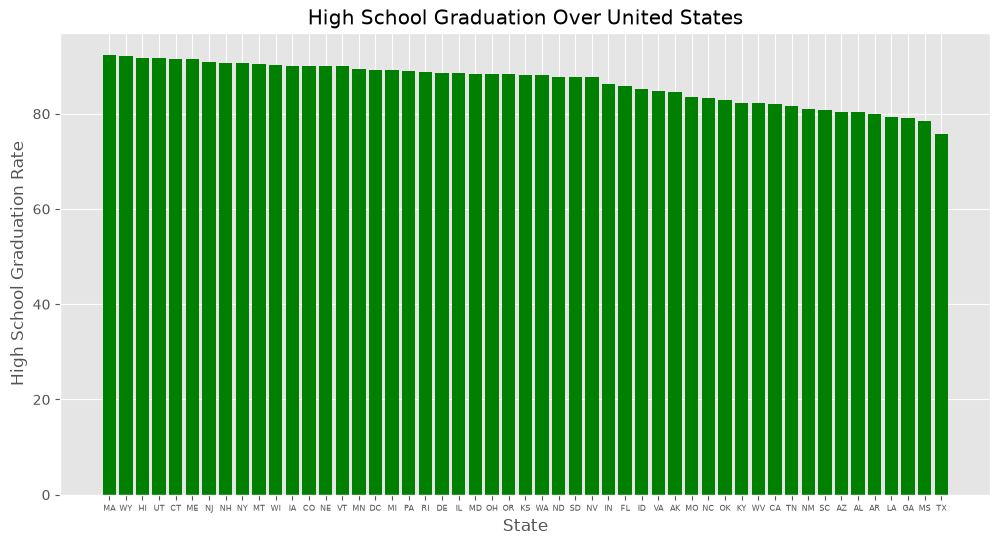

In [16]:
graduation_by_stats = df_pct_completed_hs.groupby('Geographic Area').percent_completed_hs.mean().sort_values(ascending=False)

plt.figure(figsize=(12,6))

plt.bar(x=graduation_by_stats.index, height=graduation_by_stats.values, color='green')

plt.xticks(fontsize=6)
plt.title('High School Graduation Over United States')
plt.xlabel('State')
plt.ylabel('High School Graduation Rate')

plt.show()

# The Relationship between Poverty Rates and High School Graduation Rates


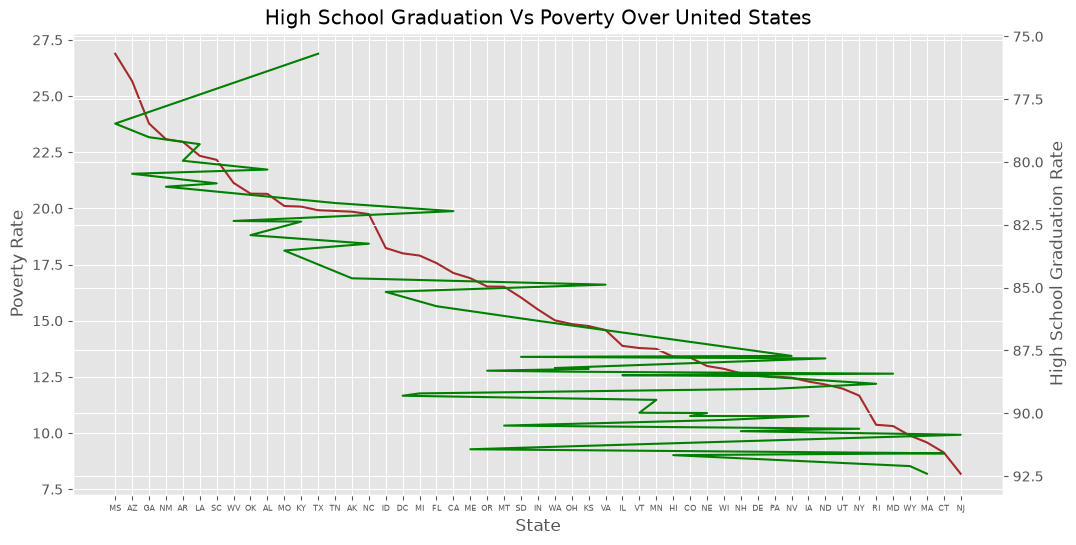

In [17]:
plt.figure(figsize=(12,6))

plt.plot(poverty_by_stats.index, poverty_by_stats.values, color='brown')
plt.xticks(fontsize=6)

plt.title('High School Graduation Vs Poverty Over United States')
plt.xlabel('State')
plt.ylabel('Poverty Rate')

ax1 = plt.gca()
ax2 = ax1.twinx()

ax2.plot(graduation_by_stats.index, graduation_by_stats.values, color='green')
ax2.invert_yaxis()

ax2.set_ylabel('High School Graduation Rate')



plt.show()

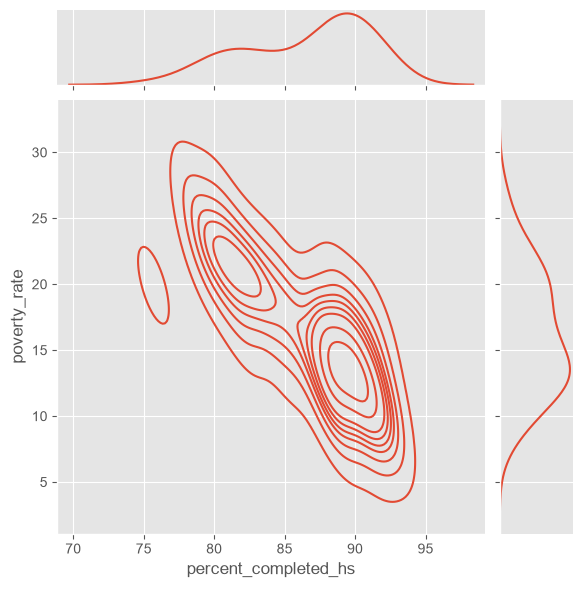

In [18]:
sns.jointplot(x=graduation_by_stats,y=poverty_by_stats, kind='kde')

sns.set_theme("paper")

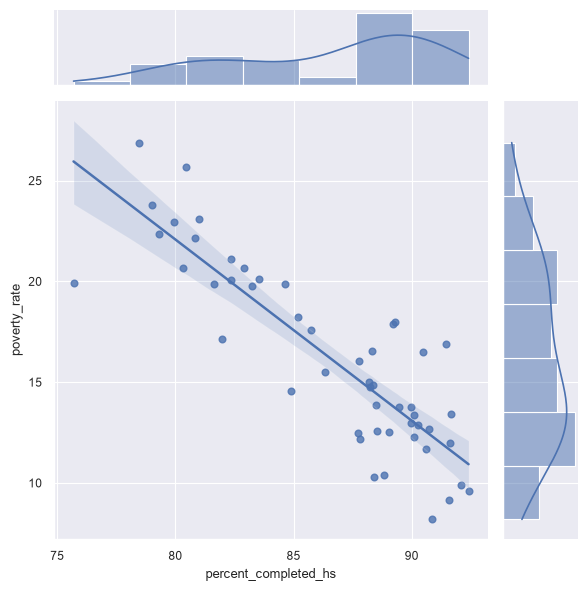

In [19]:
sns.jointplot(x=graduation_by_stats,y=poverty_by_stats, kind='reg')

sns.set_theme('poster')

<Axes: xlabel='percent_completed_hs', ylabel='poverty_rate'>

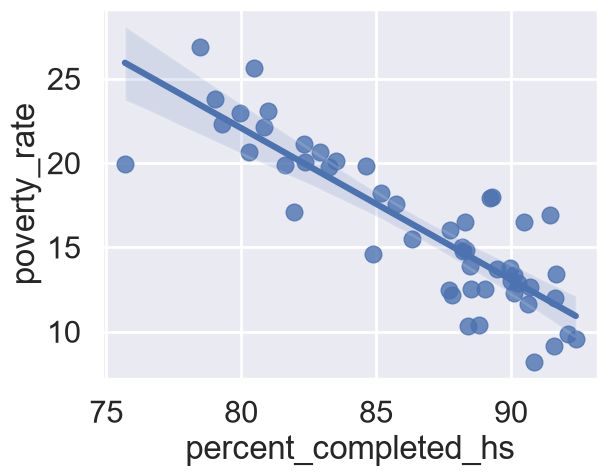

In [20]:
sns.regplot(x=graduation_by_stats.sort_index(),y=poverty_by_stats.sort_index())

# a Bar Chart with Subsections Showing the Racial Makeup of Each US State

In [21]:
for col in df_share_race_city.columns[2:]:
    df_share_race_city[col] = pd.to_numeric(df_share_race_city[col], errors='coerce')

df_share_race_city.dtypes

Geographic area              str
City                         str
share_white              float64
share_black              float64
share_native_american    float64
share_asian              float64
share_hispanic           float64
dtype: object

In [22]:
race_share = df_share_race_city.groupby('Geographic area').agg({'share_white':pd.Series.mean, 'share_black':pd.Series.mean, 'share_native_american': pd.Series.mean,'share_asian':pd.Series.mean, 'share_hispanic':pd.Series.mean}).sort_index()

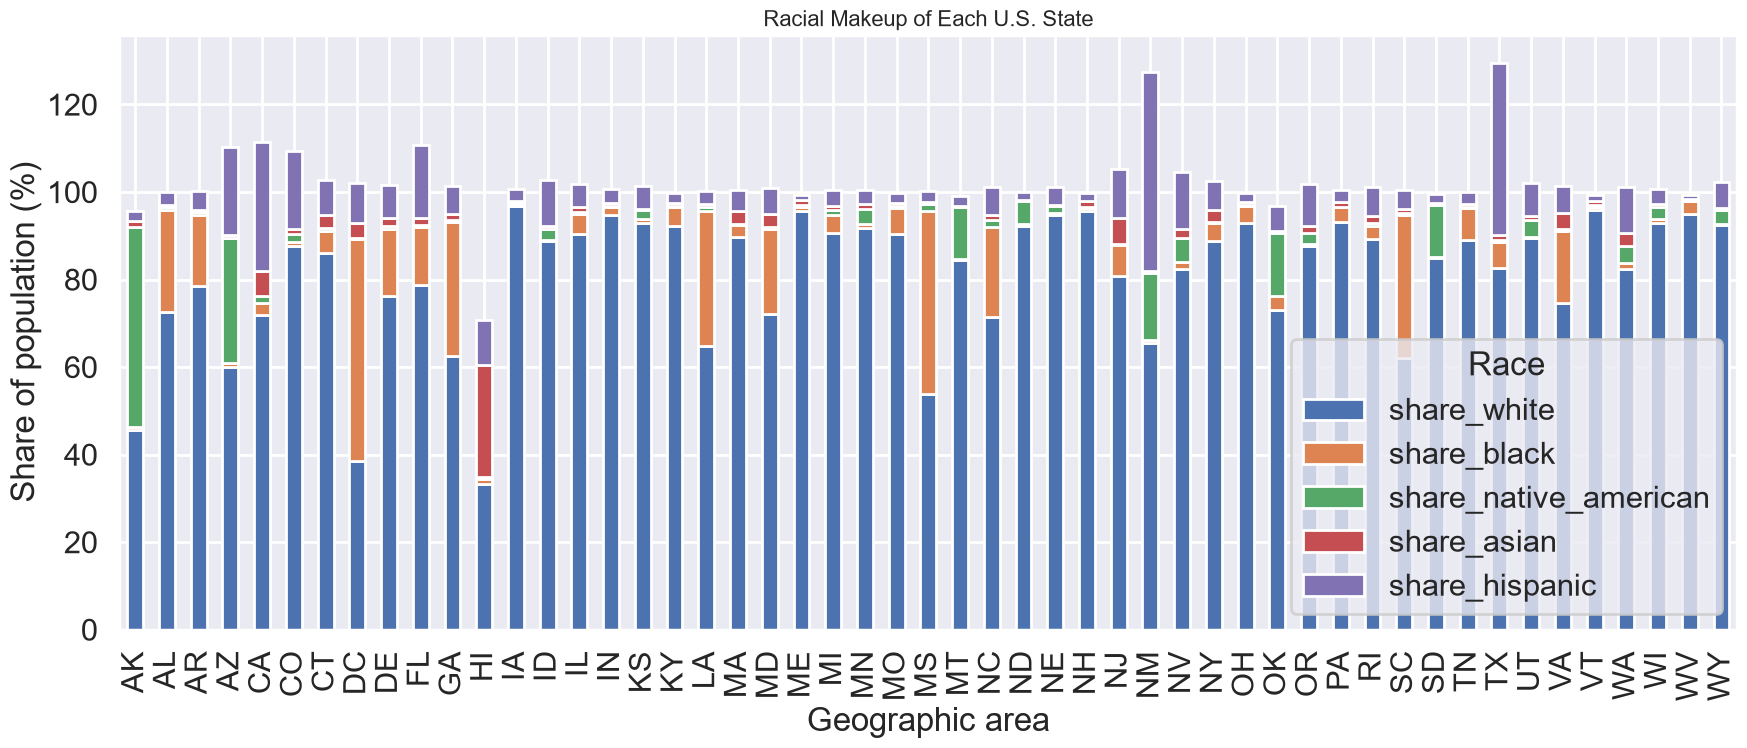

In [23]:
race_share.plot(kind="bar", stacked=True, figsize=(18, 8))
plt.title("Racial Makeup of Each U.S. State", fontsize=16)
plt.xlabel("Geographic area")
plt.ylabel("Share of population (%)")
plt.xticks(rotation=90)
plt.legend(title="Race")
plt.tight_layout()
plt.show()


# Donut Chart by of People Killed by Race


In [24]:
people_by_race = df_fatalities.race.value_counts()
people_by_race.index = ['White', 'Black', 'Hispanic', 'Unknown', 'Asian', 'Native American', 'Other']

In [25]:
fig = go.Figure(data=[go.Pie(labels= people_by_race.index,values=people_by_race, hole=.3)])

fig.update_layout(title_text="People Killed by Race")
fig.show()

# a Chart Comparing the Total Number of Deaths of Men and Women

In [26]:
male_female = df_fatalities.gender.value_counts()
male_female.index=['Male', 'Female']

In [27]:
fig = go.Figure(data=[go.Pie(labels=male_female.index, values=male_female, hole=.25)])

fig.update_layout(title_text="The Total Number of Deathes of Men and Women")
fig.show()

# a Box Plot Showing the Age and Manner of Death


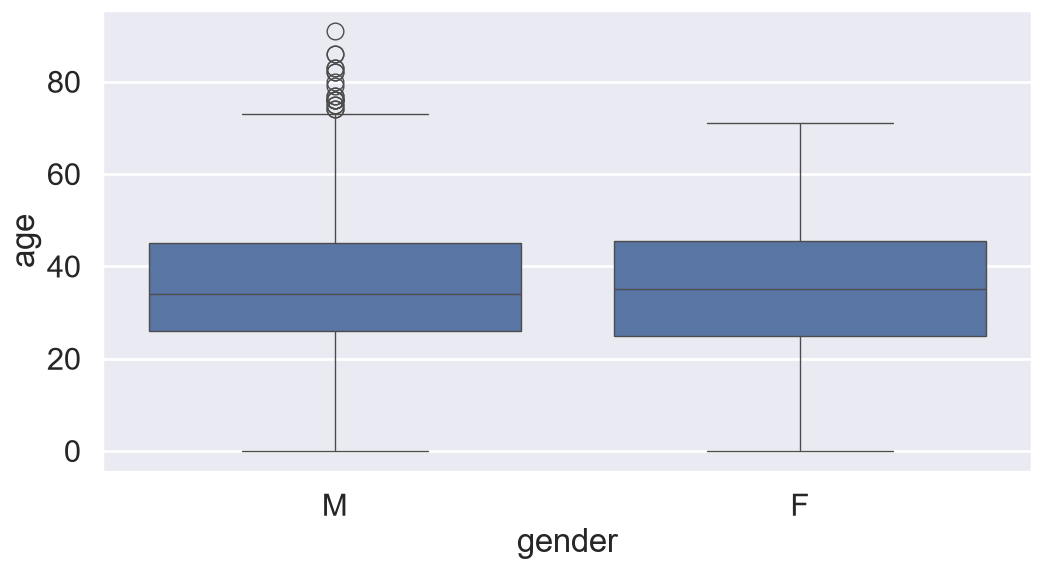

In [28]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df_fatalities, x='gender', y='age')

sns.set_theme(style="whitegrid", palette="pastel")


In [29]:
death_manner = df_fatalities.manner_of_death.value_counts()

In [30]:
fig = go.Figure(data=[go.Pie(labels=death_manner.index, values=death_manner, hole=.25)])

fig.update_layout(title_text="The Manner of Death")
fig.show()

# Were People Armed? 


In [31]:
armed = df_fatalities.armed.value_counts()[:9]

In [32]:
fig = go.Figure(data=[go.Pie(labels=armed.index, values=armed, hole=.25)])

fig.update_layout(title_text="The Manner of Death")
fig.show()

# How Old Were the People Killed?

what percentage of people killed were under 25 years old.  

In [33]:
under_25_pct = df_fatalities['age'].lt(25).mean() * 100
print(f'{under_25_pct:.2f}%')

20.79%


<Axes: xlabel='age', ylabel='Count'>

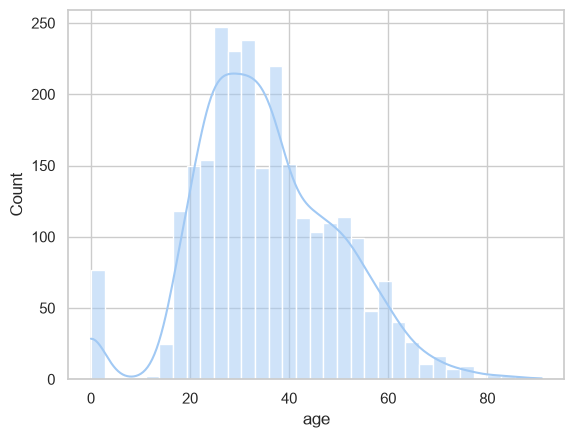

In [34]:
sns.histplot(data=df_fatalities, x='age', kde=True)

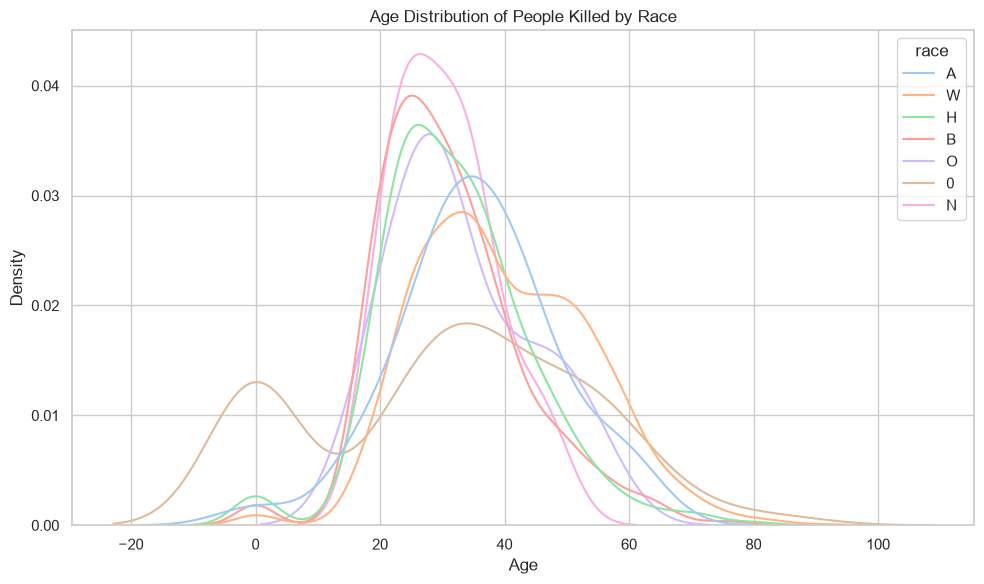

In [35]:
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df_fatalities, x='age', hue='race', common_norm=False)
plt.title('Age Distribution of People Killed by Race')
plt.xlabel('Age')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

# Race of People Killed

In [36]:
race_counts = df_fatalities['race'].fillna('Unknown').value_counts()
race_counts

race
W    1201
B     618
H     423
0     195
A      39
N      31
O      28
Name: count, dtype: int64

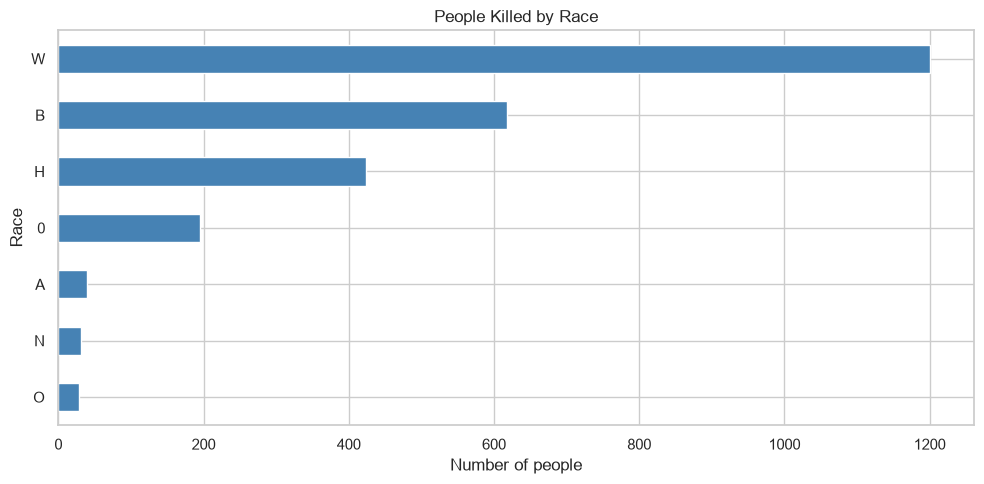

In [37]:
plt.figure(figsize=(10, 5))
race_counts.sort_values(ascending=True).plot(kind='barh', color='steelblue')
plt.title('People Killed by Race')
plt.xlabel('Number of people')
plt.ylabel('Race')
plt.tight_layout()
plt.show()

# Mental Illness and Police Killings



In [38]:
mental_illness = df_fatalities['signs_of_mental_illness'].value_counts(dropna=False)
mental_illness

signs_of_mental_illness
False    1902
True      633
Name: count, dtype: int64

In [39]:
mental_illness_pct = mental_illness.get(True, 0) / mental_illness.sum() * 100
print(f'{mental_illness_pct:.2f}% of people killed had signs of mental illness.')

24.97% of people killed had signs of mental illness.


# In Which Cities Do the Most Police Killings Take Place?



In [40]:
city_counts = df_fatalities['city'].fillna('Unknown').value_counts().head(10).sort_values()
city_counts

city
St. Louis      15
Austin         18
Miami          18
Columbus       19
San Antonio    20
Las Vegas      21
Chicago        25
Houston        27
Phoenix        31
Los Angeles    39
Name: count, dtype: int64

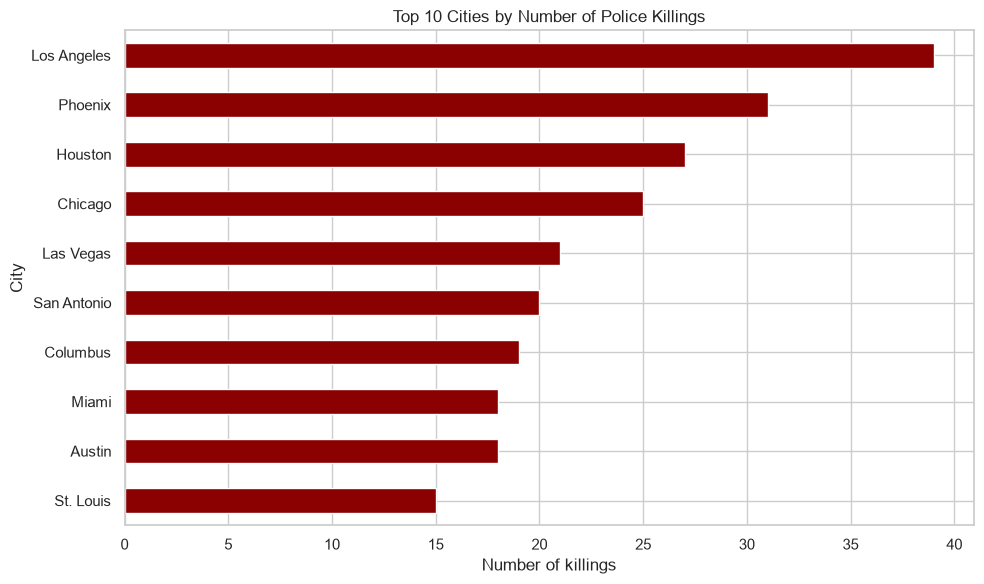

In [41]:
plt.figure(figsize=(10, 6))
city_counts.plot(kind='barh', color='darkred')
plt.title('Top 10 Cities by Number of Police Killings')
plt.xlabel('Number of killings')
plt.ylabel('City')
plt.tight_layout()
plt.show()

# Rate of Death by Race



In [42]:
top_cities = city_counts.index
top_city_fatalities = df_fatalities[df_fatalities['city'].isin(top_cities)].copy()
city_race_share = pd.crosstab(
    top_city_fatalities['city'],
    top_city_fatalities['race'].fillna('Unknown'),
    normalize='index'
) * 100
city_race_share = city_race_share.reindex(top_cities[::-1])
city_race_share.round(2)

race,0,A,B,H,N,O,W
city,,,,,,,
Los Angeles,7.69,2.56,25.64,48.72,0.00,0.00,15.38
Phoenix,9.68,0.00,6.45,35.48,9.68,0.00,38.71
Houston,3.70,3.70,55.56,22.22,3.70,0.00,11.11
Chicago,4.00,0.00,84.00,4.00,0.00,0.00,8.00
Las Vegas,19.05,0.00,14.29,23.81,0.00,0.00,42.86
San Antonio,10.00,0.00,15.00,60.00,0.00,0.00,15.00
Columbus,5.26,0.00,57.89,0.00,0.00,5.26,31.58
Miami,5.56,0.00,44.44,33.33,0.00,0.00,16.67
Austin,0.00,0.00,16.67,11.11,0.00,0.00,72.22


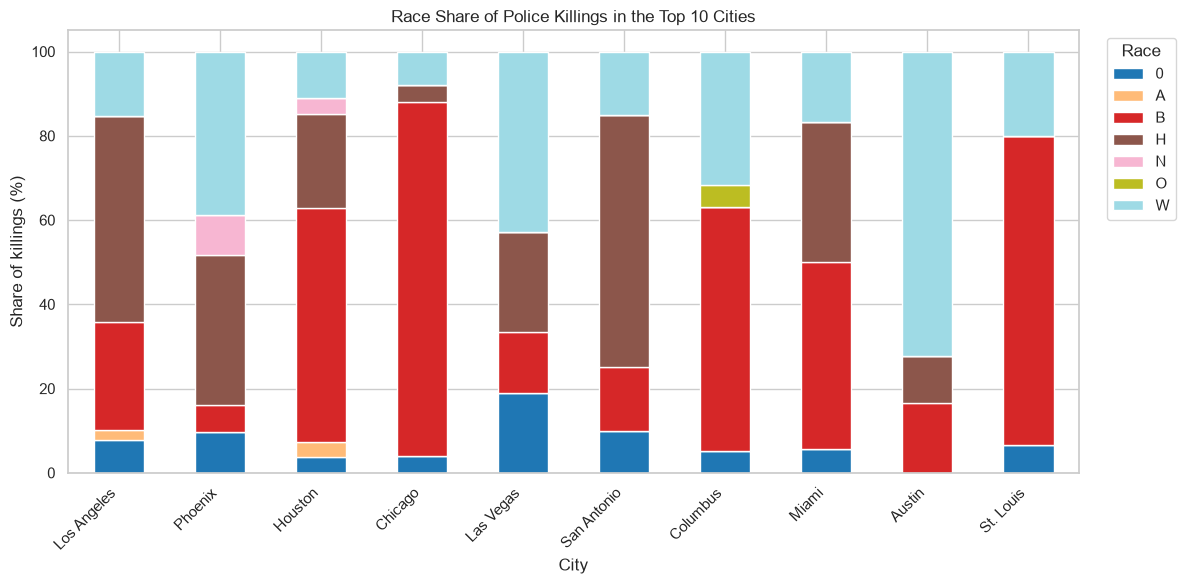

In [43]:
city_race_share.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab20')
plt.title('Race Share of Police Killings in the Top 10 Cities')
plt.xlabel('City')
plt.ylabel('Share of killings (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Race', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Create a Choropleth Map of Police Killings by US State



In [44]:
state_killings = df_fatalities['state'].value_counts().sort_values(ascending=False)
state_killings.head(10)

state
CA    424
TX    225
FL    154
AZ    118
OH     79
OK     78
CO     74
GA     70
NC     69
MO     64
Name: count, dtype: int64

In [45]:
state_map = px.choropleth(
    state_killings.rename_axis('state').reset_index(name='killings'),
    locations='state',
    locationmode='USA-states',
    color='killings',
    scope='usa',
    color_continuous_scale='Reds',
    labels={'killings': 'Police killings', 'state': 'State'}
)
state_map.update_layout(title='Police Killings by US State')
state_map.show()

# Number of Police Killings Over Time



In [46]:
df_fatalities['date'] = pd.to_datetime(df_fatalities['date'], errors='coerce')
killings_by_year = df_fatalities.groupby(df_fatalities['date'].dt.year).size()
killings_by_year

C:\Users\user\AppData\Local\Temp\ipykernel_23572\2196895385.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_fatalities['date'] = pd.to_datetime(df_fatalities['date'], errors='coerce')


date
2015    991
2016    963
2017    581
dtype: int64

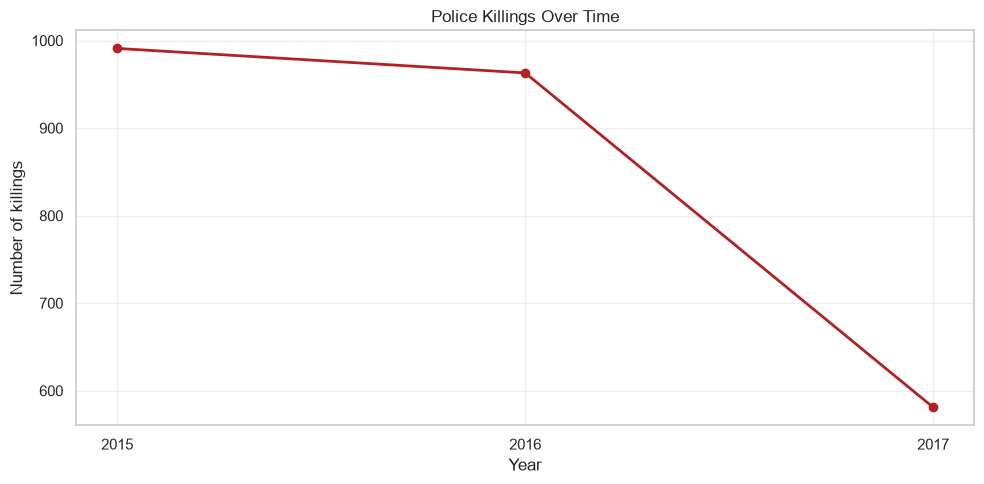

In [47]:
plt.figure(figsize=(10, 5))
killings_by_year.plot(marker='o', linewidth=2, color='firebrick')
plt.title('Police Killings Over Time')
plt.xlabel('Year')
plt.ylabel('Number of killings')
plt.xticks(killings_by_year.index.astype(int))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
monthly_killings = df_fatalities.set_index('date').resample('MS').size()
monthly_killings.tail()

date
2017-08-01    18
2017-09-01    23
2017-10-01    21
2017-11-01    16
2017-12-01    20
Freq: MS, dtype: int64

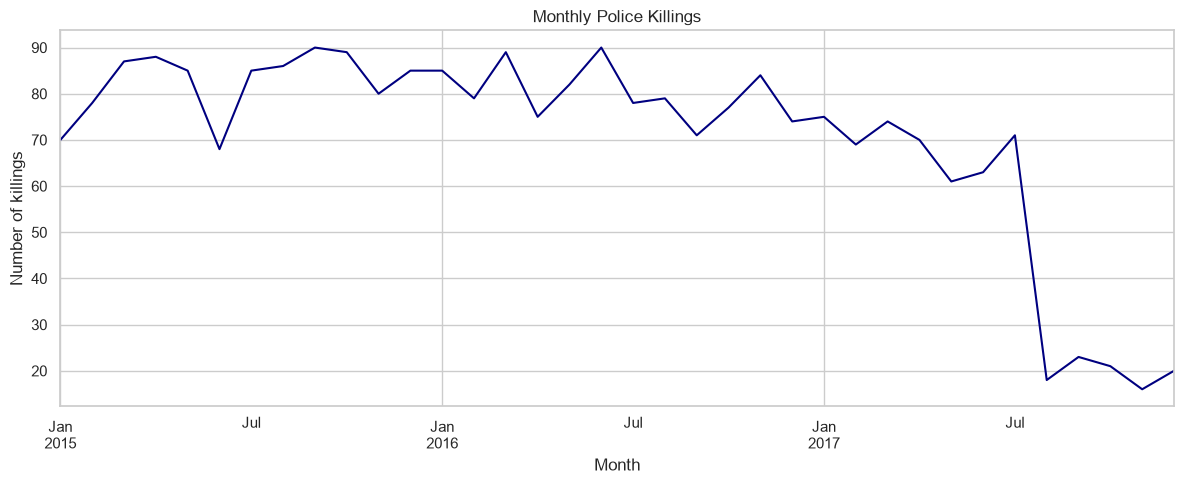

From 2015 to 2017, annual recorded killings decreased by 410.


In [49]:
plt.figure(figsize=(12, 5))
monthly_killings.plot(color='navy')
plt.title('Monthly Police Killings')
plt.xlabel('Month')
plt.ylabel('Number of killings')
plt.tight_layout()
plt.show()
change = killings_by_year.iloc[-1] - killings_by_year.iloc[0]
direction = 'increased' if change > 0 else 'decreased' if change < 0 else 'remained stable'
print(f'From {killings_by_year.index.min():.0f} to {killings_by_year.index.max():.0f}, annual recorded killings {direction} by {abs(change)}.')

# Epilogue

Now that you have analysed the data yourself, read [The Washington Post's analysis here](https://www.washingtonpost.com/graphics/investigations/police-shootings-database/).